# Synthetic Benchmark Networks for District Heating Systems
### Working notebook — Methodology II (algorithmic generation of TG/CS benchmark archetypes)


This notebook consolidates the generation pipeline described in **Section 5 (Methodology for
network archetypes generation)**:

1. **District Synthesis** — procedural urban district with centreline street grid and
   consumer substations allocated proportionally to block frontage (`DistrictGenerator`).
2. **Support Street Graph** — `networkx` graph of the street centreline network, with
   `shapely` edge geometries enabling downstream point projection (`StreetGraphBuilder`).
3. **Thermal Network Construction** — orthogonal projection of substations
   and heat source(s) onto the street graph (edge splitting), followed by a Constrained
   Steiner (CS) algorithm all terminals (`ThermalNetworkBuilder`).

## 0. Environment setup

In [60]:
import math
import random
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from shapely.geometry import Point, LineString
from networkx.algorithms.approximation import steiner_tree as nx_steiner_tree
import hashlib
import time
import matplotlib.colors as mcolors

## 1. District Synthesis — `DistrictGenerator`

In [61]:
# =====================================================================
# 1. DISTRICT GENERATOR
# =====================================================================
class DistrictGenerator:
    """
    Generates a synthetic urban district grid where roads are modelled as
    single-line centrelines to avoid double-pipe routing artefacts.

    Parameters
    ----------
    width, height    : footprint dimensions [m]
    rows, cols       : number of block rows/columns
    street_width     : uniform street width [m]
    n_substations    : total number of consumer substations
    block_variation  : relative variation of block dimensions (±fraction)
    perturbation     : max jitter on building position along frontage [m]
    seed             : random seed for full reproducibility
    """

    def __init__(self, width=1200, height=800, rows=5, cols=7,
                 street_width=15, n_substations=100,
                 block_variation=0.12, perturbation=5, seed=42):
        self.width           = width
        self.height          = height
        self.rows            = rows
        self.cols            = cols
        self.street_width    = street_width
        self.n_substations   = n_substations
        self.block_variation = block_variation
        self.perturbation    = perturbation
        self.seed            = seed

        random.seed(seed)
        self.blocks       = []
        self.buildings    = []
        self.street_nodes = {}
        self.street_edges = []
        self.street_graph = nx.Graph()

    # ------------------------------------------------------------------
    def random_partition(self, total, n):
        mean   = total / n
        values = [mean * (1 + random.uniform(-self.block_variation,
                                              self.block_variation))
                  for _ in range(n)]
        scale  = total / sum(values)
        values = [v * scale for v in values]
        values[-1] = total - sum(values[:-1])
        return values

    # ------------------------------------------------------------------
    def build_street_grid(self):
        usable_w = self.width  - (self.cols + 1) * self.street_width
        usable_h = self.height - (self.rows  + 1) * self.street_width

        self.block_widths  = self.random_partition(usable_w, self.cols)
        self.block_heights = self.random_partition(usable_h, self.rows)

        # Block boundary coordinates
        self.x = [0]
        for bw in self.block_widths:
            self.x.append(self.x[-1] + self.street_width)
            self.x.append(self.x[-1] + bw)

        self.y = [0]
        for bh in self.block_heights:
            self.y.append(self.y[-1] + self.street_width)
            self.y.append(self.y[-1] + bh)

        # Street centreline coordinates
        cx = [(self.x[i] + self.x[i+1]) / 2 if i+1 < len(self.x)
              else self.x[i] for i in range(0, len(self.x), 2)]
        cy = [(self.y[j] + self.y[j+1]) / 2 if j+1 < len(self.y)
              else self.y[j] for j in range(0, len(self.y), 2)]

        for i, x in enumerate(cx):
            for j, y in enumerate(cy):
                self.street_nodes[(i, j)] = (x, y)

        for i in range(len(cx) - 1):
            for j in range(len(cy)):
                self.street_edges.append(((i, j), (i+1, j)))
        for i in range(len(cx)):
            for j in range(len(cy) - 1):
                self.street_edges.append(((i, j), (i, j+1)))

        for node, pos in self.street_nodes.items():
            self.street_graph.add_node(node, pos=pos)
        for n1, n2 in self.street_edges:
            x1, y1 = self.street_nodes[n1]
            x2, y2 = self.street_nodes[n2]
            self.street_graph.add_edge(n1, n2,
                                       length=abs(x2-x1)+abs(y2-y1))

    # ------------------------------------------------------------------
    def build_blocks(self):
        block_id = 0
        for c in range(self.cols):
            for r in range(self.rows):
                x0 = self.x[2*c + 1]
                y0 = self.y[2*r + 1]
                self.blocks.append({
                    "id": block_id, "x": x0, "y": y0,
                    "col": c, "row": r,
                    "width":  self.block_widths[c],
                    "height": self.block_heights[r],
                    "area":   self.block_widths[c] * self.block_heights[r],
                })
                block_id += 1

    # ------------------------------------------------------------------
    def build_buildings(self):
        building_id = 0
        block_index = 0
        MARGIN  = self.street_width * 0.5
        MIN_GAP = 15.0

        for c in range(self.cols):
            for r in range(self.rows):
                block = self.blocks[block_index]
                x0, y0 = block["x"], block["y"]
                bw, bh  = block["width"], block["height"]

                available = []
                if r < self.rows - 1: available.append("N")
                if r > 0:             available.append("S")
                if c < self.cols - 1: available.append("E")
                if c > 0:             available.append("W")

                if not available:
                    block_index += 1
                    continue

                n = self._allocation[block_index]
                front_lens   = {"N": bw, "S": bw, "E": bh, "W": bh}
                avail_lens   = {s: front_lens[s] for s in available}
                total_len    = sum(avail_lens.values())
                sides_sorted = sorted(avail_lens, key=avail_lens.get,
                                      reverse=True)
                front_counts = {}
                assigned     = 0
                for i, side in enumerate(sides_sorted):
                    if i == len(sides_sorted) - 1:
                        front_counts[side] = n - assigned
                    else:
                        cnt = max(0, round(n * avail_lens[side] / total_len))
                        front_counts[side] = cnt
                        assigned += cnt

                for side, cnt in front_counts.items():
                    if cnt <= 0:
                        continue
                    if side in ("N", "S"):
                        axis_len, axis_start = bw, x0
                        fixed = y0 + bh - MARGIN if side == "N" \
                                else y0 + MARGIN
                    else:
                        axis_len, axis_start = bh, y0
                        fixed = x0 + bw - MARGIN if side == "E" \
                                else x0 + MARGIN

                    spacing = max(axis_len / (cnt + 1), MIN_GAP)
                    for k in range(cnt):
                        pos = axis_start + spacing * (k + 1)
                        pos += random.uniform(-self.perturbation,
                                              self.perturbation)
                        pos = max(axis_start + MIN_GAP,
                                  min(axis_start + axis_len - MIN_GAP, pos))
                        bx, by = (pos, fixed) if side in ("N", "S") \
                                  else (fixed, pos)
                        self.buildings.append({
                            "id": building_id,
                            "x": bx, "y": by,
                            "block": block["id"],
                        })
                        building_id += 1
                block_index += 1

    # ------------------------------------------------------------------
    def generate(self):
        self.build_street_grid()
        self.build_blocks()

        n_blocks    = len(self.blocks)
        avail_cnts  = []
        for idx in range(n_blocks):
            c, r = idx // self.rows, idx % self.rows
            cnt  = sum([r < self.rows-1, r > 0,
                        c < self.cols-1, c > 0])
            avail_cnts.append(max(cnt, 1))

        total_avail = sum(avail_cnts)
        raw         = [self.n_substations * a / total_avail
                       for a in avail_cnts]
        allocation  = [max(1, round(v)) for v in raw]
        diff        = self.n_substations - sum(allocation)
        for i in range(abs(diff)):
            allocation[i % n_blocks] += 1 if diff > 0 else -1
            allocation[i % n_blocks]  = max(0, allocation[i % n_blocks])

        self._allocation = allocation
        self.build_buildings()
        return self

    # ------------------------------------------------------------------
    def plot_district(self, ax=None, show=True, show_buildings=True):
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))
        ax.set_facecolor('#AAAAAA')
        colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']
        for idx, b in enumerate(self.blocks):
            ax.add_patch(patches.Rectangle(
                (b["x"], b["y"]), b["width"], b["height"],
                facecolor=colors[idx % len(colors)],
                edgecolor='none', zorder=1))
        if show_buildings:
            xs = [b["x"] for b in self.buildings]
            ys = [b["y"] for b in self.buildings]
            ax.scatter(xs, ys, facecolor='#CCCCFF', s=50, marker='o',
                       edgecolors='blue', linewidths=0.4, zorder=5,
                       label='Substations')
        ax.set_xlim(-20, self.width + 20)
        ax.set_ylim(-20, self.height + 20)
        ax.set_aspect('equal')
        ax.axis('off')
        if show:
            plt.tight_layout()
            plt.show()

district = DistrictGenerator(
    width=1200, height=800,
    rows=5, cols=7,
    street_width=15,
    n_substations=100,
    block_variation=0.25,
    perturbation=7,
    seed=42,
)
district.generate()
district.plot_district()
### 1.1 Demo — medium-scale district (100 substations)


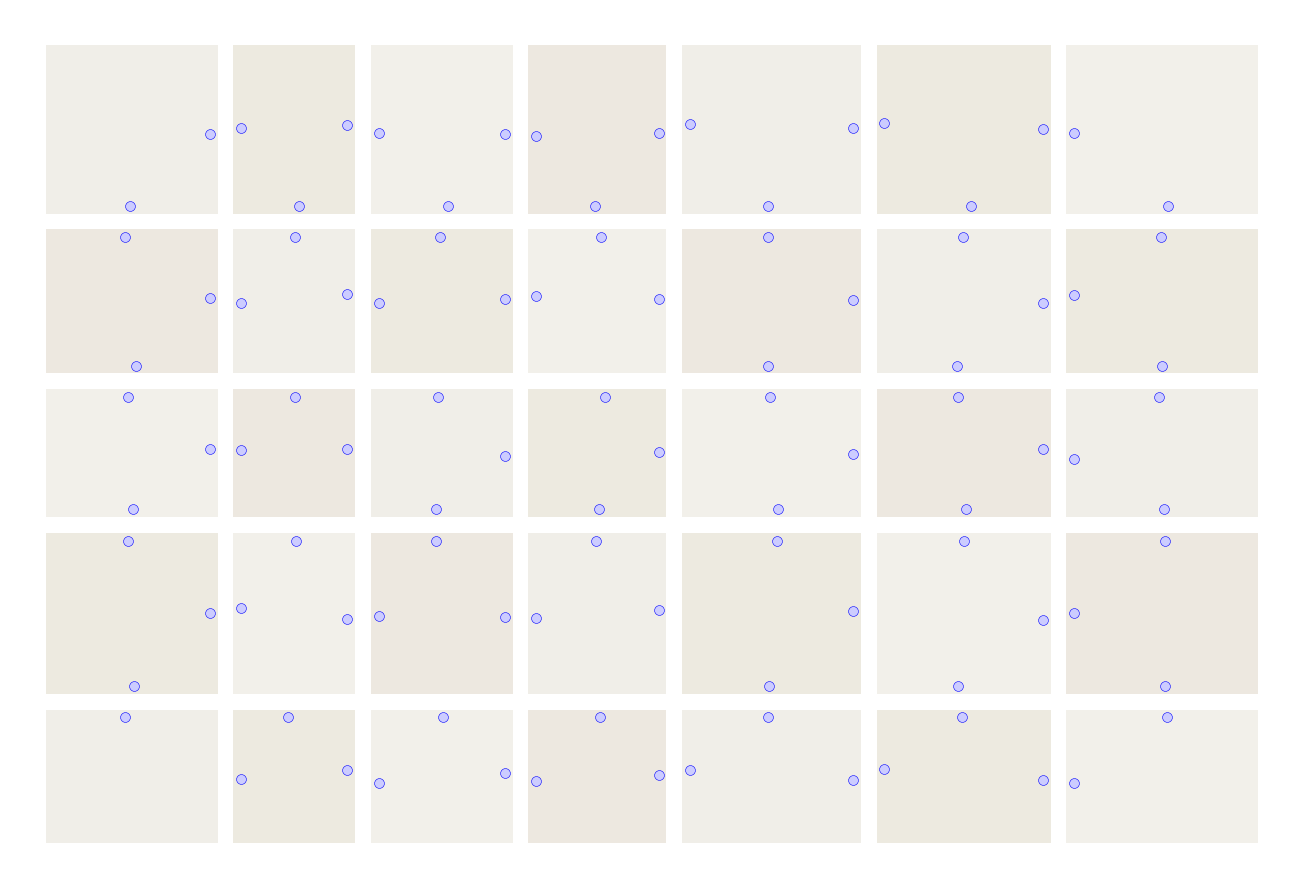

In [62]:
district = DistrictGenerator(
    width=1200, height=800,
    rows=5, cols=7,
    street_width=15,
    n_substations=100,
    block_variation=0.25,
    perturbation=7,
    seed=42,
)
district.generate()
district.plot_district()


## 2. Support Street Graph — `StreetGraphBuilder`

Builds the `networkx.Graph` support structure over the street centreline network:
- **nodes** = street intersections
- **edges** = individual street segments (one per street, no duplicates), each carrying
  `length` and a `shapely.LineString` `geometry` used for orthogonal point projection
  in Step 2/3.

The graph is validated for connectivity, a necessary condition for the Steiner Minimal
Tree computation.

In [63]:
# =====================================================================
# 2. STREET GRAPH BUILDER
# =====================================================================
class StreetGraphBuilder:
    """
    Builds and validates the support street graph starting from an already
    generated DistrictGenerator (after calling .generate()).
    """

    def __init__(self, district: DistrictGenerator):
        if not district.street_nodes:
            raise ValueError(
                "The district has not been generated: call "
                "district.generate() before building the support "
                "street graph."
            )
        self.district = district
        self.graph = nx.Graph()

    # ------------------------------------------------------------------
    def build(self) -> nx.Graph:
        d = self.district

        # --- nodes: street intersections ---
        for node_id, (x, y) in d.street_nodes.items():
            self.graph.add_node(node_id, pos=(x, y), kind="intersection")

        # --- edges: street segments (one per street, no duplicates) ---
        for n1, n2 in d.street_edges:
            x1, y1 = d.street_nodes[n1]
            x2, y2 = d.street_nodes[n2]
            length = math.hypot(x2 - x1, y2 - y1)
            geometry = LineString([(x1, y1), (x2, y2)])
            self.graph.add_edge(n1, n2, length=length, geometry=geometry,
                                 kind="street")

        self._validate()
        return self.graph

    # ------------------------------------------------------------------
    def _validate(self):
        if self.graph.number_of_nodes() == 0:
            raise ValueError("The support street graph is empty.")

        if not nx.is_connected(self.graph):
            n_comp = nx.number_connected_components(self.graph)
            raise ValueError(
                f"The support street graph is not connected "
                f"({n_comp} separate components): the Steiner Minimal Tree "
                f"(Step 3) requires a connected graph. Check the "
                f"grid generation parameters in "
                f"DistrictGenerator (rows, cols, street_width)."
            )

        # degenerate edges (near-zero length) are flagged but not blocking
        zero_len = [
            (u, v) for u, v, l in self.graph.edges(data="length")
            if l is not None and l < 1e-6
        ]
        if zero_len:
            print(f"[WARN] {len(zero_len)} near-zero-length edges detected "
                  f"in the street graph (possible geometric artefact).")

    # ------------------------------------------------------------------
    def stats(self) -> dict:
        lengths = list(nx.get_edge_attributes(self.graph, "length").values())
        return {
            "n_nodes": self.graph.number_of_nodes(),
            "n_edges": self.graph.number_of_edges(),
            "total_length_m": sum(lengths),
            "mean_edge_length_m": sum(lengths) / len(lengths) if lengths else 0.0,
            "is_connected": nx.is_connected(self.graph),
            "n_components": nx.number_connected_components(self.graph),
        }

    # ------------------------------------------------------------------
    def plot(self, ax=None, show=True, with_district=True):
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))

        if with_district:
            self.district.plot_district(ax=ax, show=False)

        pos = nx.get_node_attributes(self.graph, "pos")
        nx.draw_networkx_edges(self.graph, pos, ax=ax, edge_color="blue",
                                width=1.4, alpha=0.85)
        nx.draw_networkx_nodes(self.graph, pos, ax=ax, node_color="blue",
                                node_size=18, linewidths=0)

        ax.set_title("Support street graph",
                      fontweight="bold", fontsize=12)
        if show:
            plt.tight_layout()
            plt.show()
        return ax

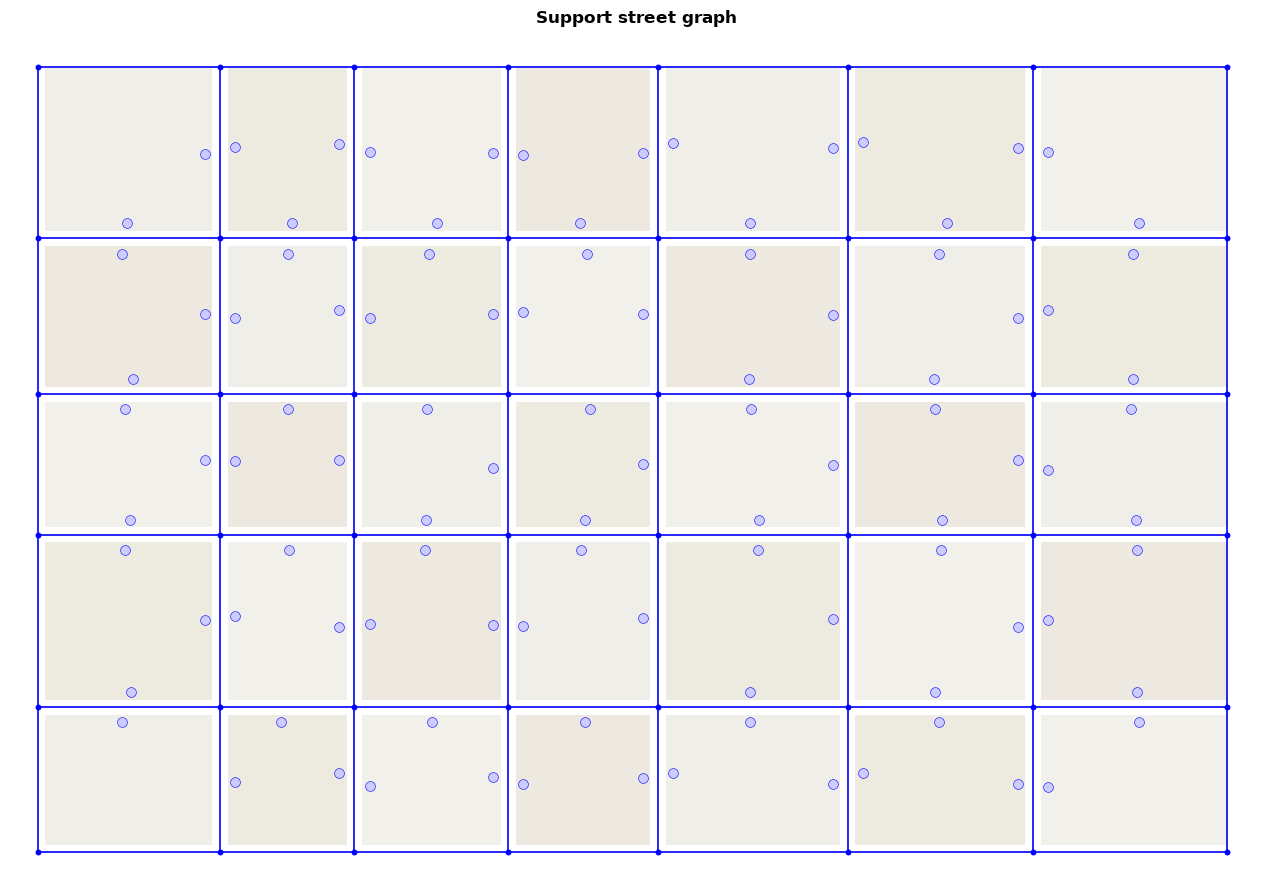

<Axes: title={'center': 'Support street graph'}>

In [64]:
builder_sg = StreetGraphBuilder(district)
street_graph = builder_sg.build()
builder_sg.stats()
builder_sg.plot()

## 3. Thermal Network Construction — `ThermalNetworkBuilder`

In [65]:
class ThermalNetworkBuilder:
    """
    Builds the DHN routing graph G_rou by orthogonally projecting the
    consumer substations and the heat source onto the support street
    graph (edge splitting), then finds the optimal DHN topology G_dhn
    via the constrained Steiner tree algorithm (Vieth et al. 2025).

    Parameters
    ----------
    street_graph    : nx.Graph — output of StreetGraphBuilder.build()
    district        : DistrictGenerator — generated district
    generator_pos   : tuple (x,y) or list of tuples [(x1,y1),(x2,y2),...]
                      Single source: (x, y)
                      Multi-source:  [(x1,y1), (x2,y2)]
    snap_tol        : float — snap tolerance [m]
    """

    _TB_ATTR = "length_tb"

    def __init__(self, street_graph, district, generator_pos, snap_tol=1.0):
        self.street_graph  = street_graph
        self.district      = district
        self.snap_tol      = snap_tol

        # Normalise: always store as list of (x,y)
        if (isinstance(generator_pos, tuple) and
                len(generator_pos) == 2 and
                not isinstance(generator_pos[0], (tuple, list))):
            self._generator_positions = [generator_pos]
        else:
            self._generator_positions = list(generator_pos)

        # Primary generator_pos (single source, backward compatible)
        self.generator_pos  = self._generator_positions[0]

        self.rou            = None
        self.dhn            = None
        self.generator_node = None      # primary source node
        self.generator_nodes = []       # all source nodes (multi-source)
        self.building_nodes  = []
        self._proj_counter   = 0

    # ------------------------------------------------------------------
    def build_routing_graph(self):
        """Projects every substation and source(s) onto the closest
        street edge, splitting it at the projection point."""
        self.rou            = self.street_graph.copy()
        self.building_nodes = []
        self.generator_nodes= []

        for b in self.district.buildings:
            node_id = self._connect_point(
                ("sub", b["id"]), b["x"], b["y"], kind="substation")
            self.building_nodes.append(node_id)

        for k, pos in enumerate(self._generator_positions):
            node_id = self._connect_point(
                ("gen", k), pos[0], pos[1], kind="generator")
            self.generator_nodes.append(node_id)

        self.generator_node = self.generator_nodes[0]
        self._assign_tiebreak_weights()

        if not nx.is_connected(self.rou):
            raise ValueError(
                "The routing graph is not connected after projection.")
        return self.rou

    # ------------------------------------------------------------------
    def _connect_point(self, node_id, x, y, kind):
        p = Point(x, y)
        best_uv, best_proj, best_dist = None, None, math.inf

        for u, v, data in self.rou.edges(data=True):
            if data.get("kind") != "street":
                continue
            geom    = data["geometry"]
            proj_pt = geom.interpolate(geom.project(p))
            d       = proj_pt.distance(p)
            if d < best_dist:
                best_uv, best_proj, best_dist = (u,v), proj_pt, d

        if best_uv is None:
            raise RuntimeError("No street edge available to project onto.")

        u, v     = best_uv
        u_pos    = self.rou.nodes[u]["pos"]
        v_pos    = self.rou.nodes[v]["pos"]
        proj_pos = (best_proj.x, best_proj.y)

        if math.dist(proj_pos, u_pos) <= self.snap_tol:
            crossing = u
        elif math.dist(proj_pos, v_pos) <= self.snap_tol:
            crossing = v
        else:
            crossing = ("proj", self._proj_counter)
            self._proj_counter += 1
            self.rou.add_node(crossing, pos=proj_pos, kind="crossing")
            self.rou.remove_edge(u, v)
            for a, a_pos, b_, b_pos in ((u, u_pos, crossing, proj_pos),
                                        (crossing, proj_pos, v, v_pos)):
                seg = LineString([a_pos, b_pos])
                self.rou.add_edge(a, b_, length=seg.length,
                                   geometry=seg, kind="street")

        self.rou.add_node(node_id, pos=(x, y), kind=kind)
        svc = LineString([(x, y), proj_pos])
        self.rou.add_edge(node_id, crossing,
                           length=max(svc.length, 1e-6),
                           geometry=svc, kind="service")
        return node_id

    # ------------------------------------------------------------------
    def _assign_tiebreak_weights(self, weight="length", eps=1e-9):
        for u, v, d in self.rou.edges(data=True):
            key = f"{u}|{v}" if str(u)<str(v) else f"{v}|{u}"
            tb  = int(hashlib.md5(key.encode()).hexdigest(),16) % 10_000 / 10_000.0
            d[self._TB_ATTR] = d[weight] * (1.0 + eps * tb)

    # ------------------------------------------------------------------
    def _add_path(self, graph, path):
        for n in path:
            if n not in graph:
                graph.add_node(n, **self.rou.nodes[n])
        for u, v in zip(path[:-1], path[1:]):
            if not graph.has_edge(u, v):
                graph.add_edge(u, v, **self.rou.edges[u, v])

    # ------------------------------------------------------------------
    def shortest_path_topology(self, weight="length"):
        """Baseline: star topology via shortest paths from generator."""
        if self.rou is None:
            raise RuntimeError("Call build_routing_graph() first.")
        _, paths = nx.single_source_dijkstra(
            self.rou, self.generator_node, weight=self._TB_ATTR)
        dhn = nx.Graph()
        dhn.add_node(self.generator_node, **self.rou.nodes[self.generator_node])
        for n in self.building_nodes:
            self._add_path(dhn, paths[n])
        return dhn

    # ------------------------------------------------------------------
    def constrained_steiner_tree(self, beta=1.25, delta_eps=0.05,
                                 weight="length"):
        if self.rou is None:
            raise RuntimeError("Call build_routing_graph() first.")
        if beta < 1:
            raise ValueError("beta must be >= 1.")

        rou       = self.rou
        tb        = self._TB_ATTR
        terminals = list(self.building_nodes)

        if len(self.generator_nodes) == 1:
            g = self.generator_nodes[0]
            sp_len, _ = nx.single_source_dijkstra(rou, g, weight=weight)
            l_sp_max = max(sp_len[n] for n in terminals)
        else:
            l_sp_max = 0.0
            for n in terminals:
                min_dist_to_any_g = math.inf
                for g in self.generator_nodes:
                    try:
                        d = nx.shortest_path_length(rou, g, n, weight=weight)
                        if d < min_dist_to_any_g:
                            min_dist_to_any_g = d
                    except nx.NetworkXNoPath:
                        continue
                if min_dist_to_any_g != math.inf:
                    l_sp_max = max(l_sp_max, min_dist_to_any_g)

        l_max = beta * l_sp_max

        dhn = nx.Graph()
        dhn.add_node(self.generator_nodes[0],
                     **rou.nodes[self.generator_nodes[0]])
        for g_extra in self.generator_nodes[1:]:
            _, path = nx.single_source_dijkstra(
                rou, self.generator_nodes[0], target=g_extra, weight=tb)
            self._add_path(dhn, path)

        unprocessed = set(terminals)

        while unprocessed:
            best_path, best_len = None, math.inf

            for r in unprocessed:
                added_len, path_r = nx.multi_source_dijkstra(
                    rou, sources=set(dhn.nodes), target=r, weight=tb)
                if added_len >= best_len:
                    continue
                dhn_hat = dhn.copy()
                self._add_path(dhn_hat, path_r)
                l_gr = math.inf
                for g in self.generator_nodes:
                    if g in dhn_hat:
                        try:
                            d = nx.shortest_path_length(dhn_hat, g, r, weight=weight)
                            if d < l_gr:
                                l_gr = d
                        except nx.NetworkXNoPath:
                            continue
                if l_gr <= l_max:
                    best_path, best_len = path_r, added_len

            if best_path is None:
                eps = delta_eps
                while True:
                    def w(u, v, d, _eps=eps):
                        c = 0.0 if dhn.has_edge(u, v) else d[tb]
                        return _eps * d[tb] + (1.0 - _eps) * c

                    w_len, w_paths = nx.multi_source_dijkstra(
                        rou, sources=set(self.generator_nodes), weight=w)
                    reachable = {n: w_len[n] for n in unprocessed if n in w_len}
                    if not reachable:
                        break
                    r      = min(reachable, key=reachable.get)
                    path_r = w_paths[r]
                    dhn_hat = dhn.copy()
                    self._add_path(dhn_hat, path_r)
                    l_gr = math.inf
                    for g in self.generator_nodes:
                        if g in dhn_hat:
                            try:
                                d = nx.shortest_path_length(dhn_hat, g, r, weight=weight)
                                if d < l_gr:
                                    l_gr = d
                            except nx.NetworkXNoPath:
                                continue
                    if l_gr <= l_max or eps >= 1.0:
                        best_path = path_r
                        break
                    eps = min(eps + delta_eps, 1.0)

            if best_path is not None:
                self._add_path(dhn, best_path)
                unprocessed.remove(best_path[-1])
            else:
                r = unprocessed.pop()
                _, path_r = nx.multi_source_dijkstra(
                    rou, sources=set(dhn.nodes), target=r, weight=tb)
                self._add_path(dhn, path_r)

        self.dhn = dhn
        return dhn

    # ------------------------------------------------------------------
    def steiner_tree_topology(self, weight="length", method="kou"):
        """Unconstrained Steiner tree (Kou/Mehlhorn via networkX)."""
        if self.rou is None:
            raise RuntimeError("Call build_routing_graph() first.")
        terminals = set(self.building_nodes) | set(self.generator_nodes)
        try:
            return nx_steiner_tree(self.rou, terminals,
                                    weight=weight, method=method)
        except TypeError:
            return nx_steiner_tree(self.rou, terminals, weight=weight)

    # ------------------------------------------------------------------
    def metrics(self, dhn=None):
        """Topological metrics. Supports multi-source configurations."""
        dhn = dhn if dhn is not None else self.dhn
        if dhn is None:
            raise RuntimeError("No DHN topology available.")

        l_tot = sum(d.get("length", 0.0) for _, _, d in dhn.edges(data=True))

        l_cc = 0.0
        for n in self.building_nodes:
            if n not in dhn:
                continue
            min_dist_to_any_g = math.inf
            for g in self.generator_nodes:
                if g in dhn:
                    try:
                        d = nx.shortest_path_length(dhn, g, n, weight="length")
                        if d < min_dist_to_any_g:
                            min_dist_to_any_g = d
                    except nx.NetworkXNoPath:
                        continue
            if min_dist_to_any_g != math.inf:
                l_cc = max(l_cc, min_dist_to_any_g)

        N = dhn.number_of_nodes()
        E = dhn.number_of_edges()
        C = nx.number_connected_components(dhn)
        L = E - N + C          # formula generale: L=0 se albero, L>0 se loop

        return {
            "L_tot_m"    : round(l_tot, 2),
            "L_cc_m"     : round(l_cc,  2),
            "N_nodes"    : N,
            "N_edges"    : E,
            "N_components": C,
            "L_loops"    : L,
            "alpha"      : round(L / max(2*N-5, 1), 4),
            "is_meshed"  : L > 0 and C == 1,
            "connected"  : C == 1,
        }

    # ------------------------------------------------------------------
    def plot(self, dhn=None, ax=None, show=True,
             with_district=True, title="DHN_TG_3G_M_M_BASE"):

        dhn = dhn if dhn is not None else self.dhn

        if dhn is None:
            raise RuntimeError("No DHN topology to plot.")

        if ax is None:

            fig, ax = plt.subplots(figsize=(14,9))

        if with_district:
            self.district.plot_district(ax=ax, show=False)

        pos = nx.get_node_attributes(self.rou, "pos")

        # edges
        nx.draw_networkx_edges(dhn, pos, ax=ax,
                               edge_color="black", width=1.0, alpha=1.0)

        # substations
        sub_nodes = [n for n in dhn.nodes if n in self.building_nodes]

        nx.draw_networkx_nodes(dhn, pos, nodelist=sub_nodes, ax=ax,
                               node_color="#CCCCFF", node_size=22,
                               edgecolors="blue", linewidths=1.2)

        # source
        nx.draw_networkx_nodes(dhn, pos, nodelist=self.generator_nodes, ax=ax,
                               node_color="blue", node_size=140,
                               edgecolors="blue", linewidths=1.2)

        # internal junctions
        junction_nodes = [n for n in dhn.nodes
                          if n not in self.building_nodes
                          and n not in self.generator_nodes]

        nx.draw_networkx_nodes(dhn, pos, nodelist=junction_nodes, ax=ax,
                               node_color="black", node_size=22, linewidths=0)

        ax.set_title(title, fontweight="bold", fontsize=12)

        if show:
            plt.tight_layout(); plt.show()

        return ax

### 3.1 Single-source test — DHN_TG_3G_M_M_BASE


DHN_TG_3G_M_M_BASE:
  L_tot_m      8613.38
  L_cc_m       1705.43
  N_nodes      221
  N_edges      224
  N_components 1
  L_loops      4
  alpha        0.0092
  is_meshed    True
  connected    True


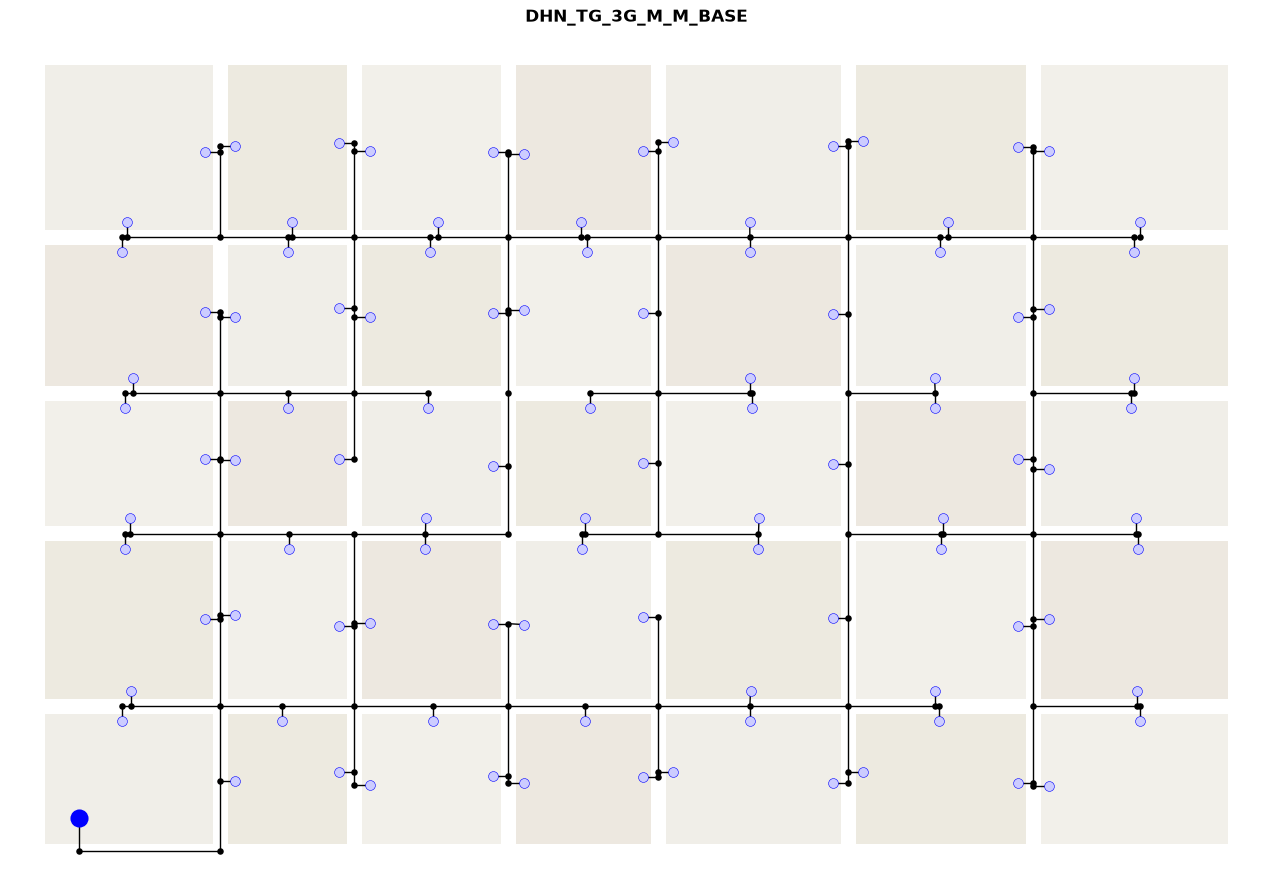

<Axes: title={'center': 'DHN_TG_3G_M_M_BASE'}>

In [66]:
BETA = 1.00

src_block = district.blocks[0 * district.rows + 0]
gen_pos   = (src_block["x"] + src_block["width"]  / 5,
             src_block["y"] + src_block["height"] / 5)

tnb = ThermalNetworkBuilder(street_graph, district, gen_pos)
tnb.build_routing_graph()
dhn = tnb.constrained_steiner_tree(beta=BETA)
#dhn = tnb.add_mesh_layers(max_extra_edges=5)

m = tnb.metrics(dhn)
print("DHN_TG_3G_M_M_BASE:")
for k, v in m.items(): print(f"  {k:<12} {v}")

tnb.plot(dhn=dhn, title="DHN_TG_3G_M_M_BASE")

### 3.2 Multi-source test — DHN_TG_4G_M_M_BASE

src0: (48.083853529920574, 40.71656805347961)
src1: (928.9376411871567, 411.94318088574425)

DHN_TG_4G_M_M_BASE:
  L_tot_m      8519.12
  L_cc_m       919.53
  N_nodes      223
  N_edges      224
  N_components 1
  L_loops      2
  alpha        0.0045
  is_meshed    True
  connected    True


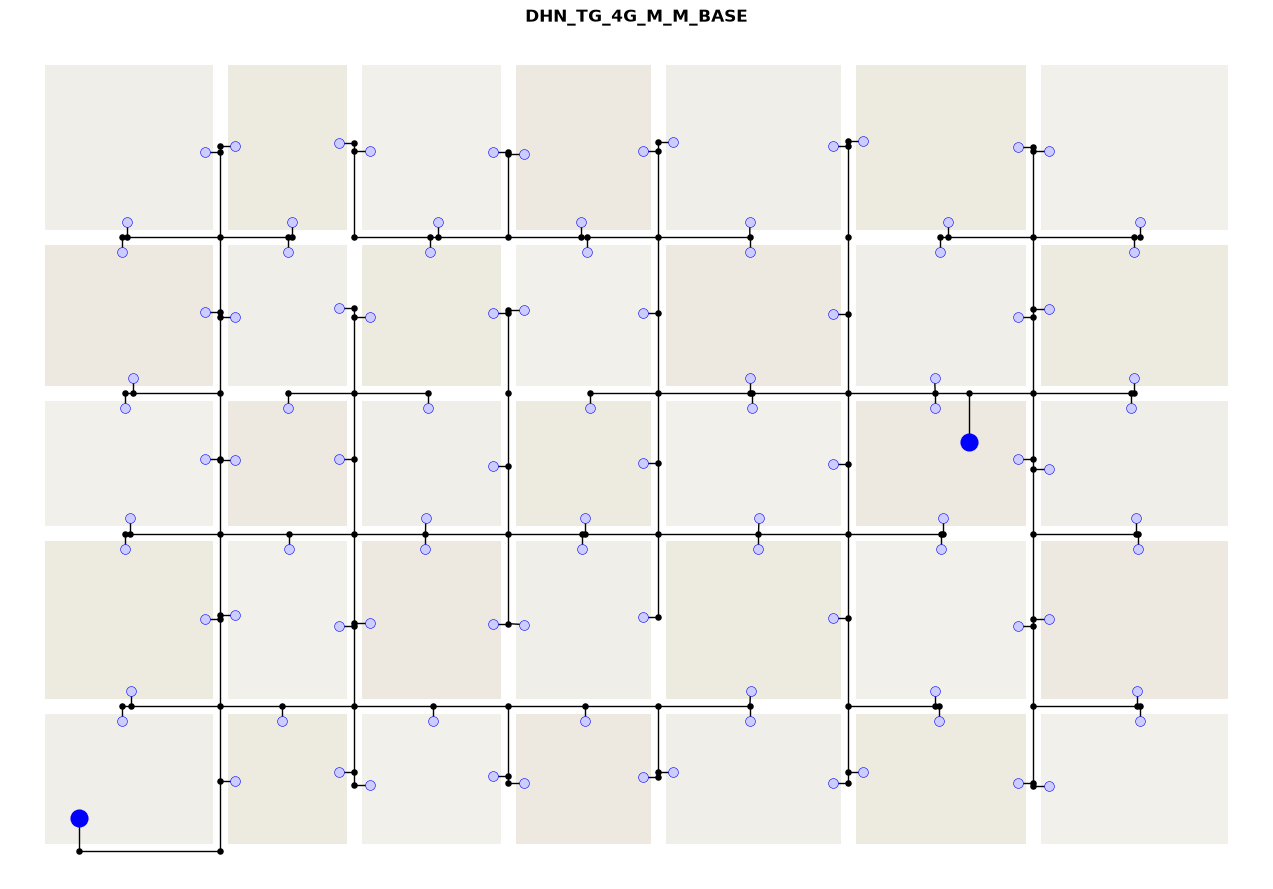

<Axes: title={'center': 'DHN_TG_4G_M_M_BASE'}>

In [67]:
BETA = 1.00
COLS, ROWS = 7, 5

# src0
src0_block = district.blocks[0 * district.rows + 0]
gen_pos0   = (src0_block["x"] + src0_block["width"]  / 5,
              src0_block["y"] + src0_block["height"] / 5)

# src1
src1_col   = int(COLS * 0.75)
src1_row   = ROWS // 2
src1_block = district.blocks[src1_col * district.rows + src1_row]
gen_pos1   = (src1_block["x"] + src1_block["width"]  * 2/3,
              src1_block["y"] + src1_block["height"] * 2/3)


print(f"src0: {gen_pos0}")
print(f"src1: {gen_pos1}")

tnb4 = ThermalNetworkBuilder(street_graph, district,
                              generator_pos=[gen_pos0, gen_pos1])
tnb4.build_routing_graph()
dhn4 = tnb4.constrained_steiner_tree(beta=BETA)
#dhn4 = tnb4.add_mesh_layers(max_extra_edges=5)

m4 = tnb4.metrics(dhn4)
print("\nDHN_TG_4G_M_M_BASE:")
for k, v in m4.items(): print(f"  {k:<12} {v}")

tnb4.plot(dhn=dhn4, title="DHN_TG_4G_M_M_BASE")

### 3.3 Prosumership test — DHN_TG_5G_M_M_BASE


DHN_TG_5G_M_M_BASE:
  L_tot_m      8613.38
  L_cc_m       1705.43
  N_nodes      221
  N_edges      224
  N_components 1
  L_loops      4
  alpha        0.0092
  is_meshed    True
  connected    True
  Prosumer: building 54 @ (606,700)
  Prosumer: building 97 @ (1008,544)
  Prosumer: building 90 @ (1095,166)
  Prosumer: building 14 @ (249,136)
  Prosumer: building 9 @ (173,541)


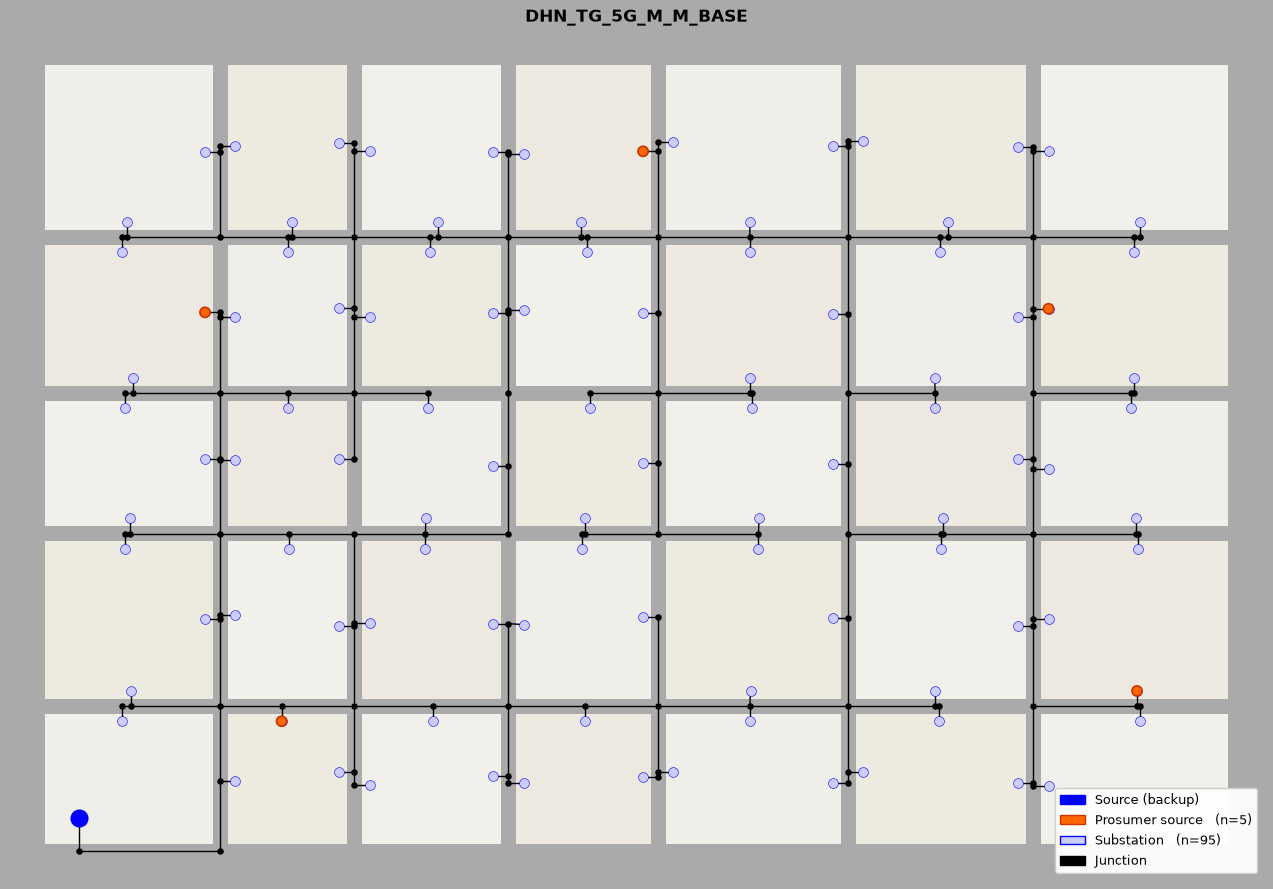

In [68]:
BETA = 1.00

# Backup source — bottom-left peripheral (col=0, row=0)
src_block  = district.blocks[0 * district.rows + 0]
backup_pos = (src_block["x"] + src_block["width"]  / 5,
              src_block["y"] + src_block["height"] / 5)

tnb5 = ThermalNetworkBuilder(street_graph, district, backup_pos)
tnb5.build_routing_graph()
dhn5 = tnb5.constrained_steiner_tree(beta=BETA)
#dhn5 = tnb5.add_mesh_layers(max_extra_edges=5)

m5 = tnb5.metrics(dhn5)
print("DHN_TG_5G_M_M_BASE:")
for k, v in m5.items(): print(f"  {k:<12} {v}")

# Prosumer source selection — 5% of substations, spatially distributed
N_PROSUMER_SRC = 5
WIDTH, HEIGHT   = district.width, district.height
zone_centroids  = [
    (WIDTH * 0.50, HEIGHT * 0.85),   # North
    (WIDTH * 0.85, HEIGHT * 0.65),   # NE
    (WIDTH * 0.85, HEIGHT * 0.20),   # SE
    (WIDTH * 0.15, HEIGHT * 0.20),   # SW
    (WIDTH * 0.15, HEIGHT * 0.65),   # NW
]
prosumer_ids = []
used         = set()
for zx, zy in zone_centroids:
    best_d, best_b = float("inf"), None
    for b in district.buildings:
        if b["id"] in used: continue
        d = math.hypot(b["x"]-zx, b["y"]-zy)
        if d < best_d:
            best_d, best_b = d, b
    prosumer_ids.append(best_b["id"])
    used.add(best_b["id"])
    print(f"  Prosumer: building {best_b['id']} "
          f"@ ({best_b['x']:.0f},{best_b['y']:.0f})")

prosumer_set = set(prosumer_ids)

tnb5.plot(dhn=dhn5,
          title="DHN_TG_5G_M_M_BASE",
          show=False)

ax      = plt.gca()
fig     = plt.gcf()
fig.patch.set_facecolor('#AAAAAA')
ax.set_facecolor('#AAAAAA')

# Overlay prosumer sources — orange circles
pos_rou = nx.get_node_attributes(tnb5.rou, "pos")
for n in tnb5.building_nodes:
    b_idx = tnb5.building_nodes.index(n)
    if b_idx in prosumer_set:
        x, y = pos_rou[n]
        ax.add_patch(plt.Circle((x, y), radius=5,
                                facecolor="#FF6600",
                                edgecolor="#CC3300",
                                linewidth=1.2, zorder=6))

# Legend
import matplotlib.patches as mpatches
legend_elements = [
    mpatches.Patch(facecolor="blue",    edgecolor="blue",
                   label="Source (backup)"),
    mpatches.Patch(facecolor="#FF6600", edgecolor="#CC3300",
                   label=f"Prosumer source   (n={N_PROSUMER_SRC})"),
    mpatches.Patch(facecolor="#CCCCFF", edgecolor="blue",
                   label=f"Substation   (n={len(district.buildings)-N_PROSUMER_SRC})"),
    mpatches.Patch(facecolor="black",   edgecolor="black",
                   label="Junction"),
]
ax.legend(handles=legend_elements,
          loc="lower right", fontsize=9, framealpha=0.95)

plt.tight_layout()
plt.show()